# 02. N-CMAPSS DS02 — Ensamble de stacking híbrido (protocolo honesto)

**Qué predecimos.** La vida útil restante (RUL) de un motor turbofán, en ciclos
de vuelo, a partir de una ventana de 50 lecturas de sensores.

- **Tipo de problema:** regresión sobre series temporales, con los motores
  agrupados: ninguna ventana de un motor aparece a la vez en ajuste y en test.
- **Métrica principal:** RMSE, en ciclos. Se informan también MAE, R² y la
  puntuación asimétrica de la NASA, que castiga más pasarse de RUL que quedarse
  corto.
- **Qué vas a hacer:** ejecutar las celdas en orden y leer lo que imprimen. El
  código ya está escrito; el trabajo es interpretar tablas y gráficos.
- **Lo que cambia en esta revisión:** el protocolo, no el modelo. Los números de
  la versión anterior no eran comparables porque había fuga de información.

**Qué es.** Un predictor de RUL para N-CMAPSS DS02 construido como ensamble de
stacking: un BiLSTM sobre ventanas ordenadas, un LightGBM cuantílico sobre un
resumen tabular residualizado, un meta-aprendiz, un factor de contracción
`beta` y una EMA causal por motor.

**Qué cambió en esta revisión** (la versión anterior conservaba los números pero
no el protocolo):

| Defecto | Corrección |
| --- | --- |
| `scaler`, `scaler_w`, `poly_w` y los 14 `Ridge` de residuos se ajustaban sobre los seis motores dev, holdout incluido | El reparto por motor ocurre ahora **primero**; toda transformación se ajusta solo con los cinco motores de ajuste |
| `beta` se elegía sobre las mismas filas del motor 16 que ajustaron los meta-aprendices (RMSE de validación 0,308 frente a 4,221 del BiLSTM) | `beta` se elige por validación cruzada agrupada **fuera de fold**; el protocolo dentro de muestra se conserva solo como diagnóstico etiquetado |
| `ensemble.joblib` no se podía cargar fuera del notebook (`__main__`) y su `Lambda` lo ataba a una versión menor de Python | Las clases viven en `src/ds02_rul`; el grafo se persiste de forma nativa como `.keras` con una capa de pooling registrada |
| El fallback de FD001 podía sobrescribir en silencio el artefacto de DS02 | El cargador lanza un error en vez de hacer fallback |
| Las afirmaciones sobre el costo de `cyc_norm` se citaban de una iteración no relacionada | La ablación de abajo lo **mide** |

Todo lo de acá es un único diseño medido con tres semillas: la dispersión entre
semillas se informa al lado de la media para que no se confunda con precisión.


## 0 · Entorno y semillas

Dos avisos antes de empezar:

- **Duración.** El notebook completo tarda unos 30 minutos. Cuatro celdas se
  llevan casi todo el tiempo: `run_seed` (sección 5), la ablación (sección 6),
  las predicciones fuera de fold (sección 7) y las dos semillas extra
  (sección 9). Cada una imprime lo que tardó.
- **Orden.** Las secciones se ejecutan de arriba abajo. Ninguna celda funciona
  suelta: todas leen variables que dejó la anterior.


In [1]:
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import numpy as np
import pandas as pd

import ds02_rul
from ds02_rul import calculate_nasa_score, evaluate_predictions, macro_rmse
from ds02_rul.conformal import apply_conformal, empirical_coverage, fit_conformal
from ds02_rul.data import load_ds02
from ds02_rul.features import build_windows, fit_preprocessing
from ds02_rul.model import build_champion_bilstm
from ds02_rul.persistence import build_manifest, load_ensemble, save_ensemble
from ds02_rul.smoothing import causal_ema_by_unit
from ds02_rul.stacking import (
    fit_meta_learners, in_sample_beta_diagnostic, meta_predict, select_beta_grouped,
)
from ds02_rul.pipeline import (
    ablation_table, make_lgbm, oof_base_predictions, run_seed, seed_summary,
)

import keras
import lightgbm as lgb
import sklearn

SEEDS = [42, 7, 123]
PRIMARY_SEED = SEEDS[0]
WINDOW_SIZE = 50
STEP_TRAIN = 3
STEP_TEST = 2

print('python  :', sys.version.split()[0])
print('keras   :', keras.__version__)
print('lightgbm:', lgb.__version__)
print('sklearn :', sklearn.__version__)
print('ds02_rul:', ds02_rul.__version__, '->', os.path.dirname(ds02_rul.__file__))


python  : 3.12.10
keras   : 3.15.1
lightgbm: 4.7.0
sklearn : 1.9.1
ds02_rul: 4.1.0 -> C:\Users\mikel\Desktop\Pruebas\nasa\src\ds02_rul


### Utilidades de presentación

Las funciones de abajo no entrenan nada: reciben tablas y predicciones ya
calculadas y solo las formatean o las dibujan. Están acá arriba para que el
resto del notebook se lea como una narración y no como veinte celdas sueltas:
cambiar un color o un decimal se hace en un solo sitio.


In [2]:
# --- utilidades de presentación: importaciones ---
# `plt` se importa aquí, no en la celda de persistencia: las funciones
# de abajo lo usan y esa celda se ejecuta después de todos los gráficos.
import matplotlib.pyplot as plt

# --- paleta y etiquetas -----------------------------------------------------
# Un color por modelo, el mismo en todos los gráficos. Así el lector reconoce
# la serie sin volver a leer la leyenda.
PALETA = {
    'LightGBM solo': '#8C8C8C',
    'BiLSTM solo': '#4C72B0',
    'Híbrido + EMA5': '#1FA098',
}
COLORES_ABLACION = {'LGBM': '#8C8C8C', 'BiLSTM': '#4C72B0', 'BiLSTM+EMA': '#1FA098'}
NOMBRE_CORTO = {'LightGBM solo': 'LightGBM', 'BiLSTM solo': 'BiLSTM'}


def nombre_corto(modelo):
    """Etiqueta corta para los ejes; no toca el nombre que usan las tablas."""
    return NOMBRE_CORTO.get(modelo, modelo)


# --- tablas -----------------------------------------------------------------
def tabla_modelos(summary, metricas=('RMSE', 'MAE', 'R2', 'NASA_Score')):
    """Una fila por modelo con 'media ± desviación' en cada métrica.

    Ordena por RMSE medio y devuelve strings: es una tabla para leer, no para
    volver a calcular. Los decimales se eligen por métrica para que el ruido de
    las últimas cifras no se confunda con una diferencia.
    """
    orden = summary.sort_values('RMSE_mean')
    filas = []
    for _, fila in orden.iterrows():
        registro = {'Modelo': fila['Modelo']}
        for metrica in metricas:
            decimales = {'R2': 4, 'NASA_Score': 1}.get(metrica, 3)
            registro[metrica] = (f"{fila[f'{metrica}_mean']:.{decimales}f}"
                                 f" ± {fila[f'{metrica}_std']:.{decimales}f}")
        filas.append(registro)
    return pd.DataFrame(filas)


def comparar_con_base(summary, base, metricas=('RMSE', 'MAE')):
    """Cuánto mejora (o empeora) cada modelo frente a la base indicada.

    El delta es la diferencia directa de medias: negativo en RMSE/MAE significa
    que se equivoca menos. La columna 'mejora %' ya viene en positivo cuando
    mejora, para poder decirla en voz alta sin cambiar de signo.
    """
    fila_base = summary.loc[summary['Modelo'] == base].iloc[0]
    filas = []
    for _, fila in summary.sort_values('RMSE_mean').iterrows():
        registro = {'Modelo': fila['Modelo'], 'frente a': base}
        for metrica in metricas:
            delta = fila[f'{metrica}_mean'] - fila_base[f'{metrica}_mean']
            registro[f'delta {metrica}'] = round(float(delta), 3)
            registro[f'mejora {metrica} %'] = round(-100 * float(delta) / float(fila_base[f'{metrica}_mean']), 1)
        filas.append(registro)
    return pd.DataFrame(filas)


def tabla_por_motor(y_real, y_pred, unidades):
    """RMSE, MAE y sesgo de cada motor de test, por separado.

    Un promedio bueno puede esconder un motor malo: si un motor concentra el
    error, el número global no describe al modelo.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    unidades = np.asarray(unidades)
    filas = []
    for unidad in sorted(np.unique(unidades).tolist()):
        mask = unidades == unidad
        error = y_pred[mask] - y_real[mask]
        filas.append({
            'Motor': int(unidad),
            'Ventanas': int(mask.sum()),
            'RMSE': round(float(np.sqrt(np.mean(error ** 2))), 3),
            'MAE': round(float(np.mean(np.abs(error))), 3),
            'Sesgo': round(float(error.mean()), 3),
        })
    return pd.DataFrame(filas)


# --- gráficos ---------------------------------------------------------------
def barras_metricas(summary, metricas=('RMSE', 'MAE', 'R2', 'NASA_Score'), figsize=(11, 7)):
    """Barras horizontales de la media, con la desviación entre semillas como error.

    La rayita es la desviación: si dos barras se diferencian menos que eso, es
    un empate y no hay que elegir por el tercer decimal.
    """
    orden = summary.sort_values('RMSE_mean')
    etiquetas = [nombre_corto(m) for m in orden['Modelo']]
    colores = [PALETA.get(m, '#999999') for m in orden['Modelo']]

    fig, axes = plt.subplots(2, 2, figsize=figsize)
    for ax, metrica in zip(axes.ravel(), metricas):
        ax.barh(etiquetas, orden[f'{metrica}_mean'].values,
                xerr=orden[f'{metrica}_std'].values, color=colores, capsize=5)
        ax.set_title(metrica)
        ax.set_xlabel('media ± desviación entre semillas')
        ax.grid(True, axis='x', ls='--', alpha=0.5)
        ax.invert_yaxis()
    fig.suptitle('Comparación de modelos sobre los motores 11/14/15', y=1.01)
    plt.tight_layout()
    plt.show()


def dispersion_por_semilla(seed_rows, metrica='RMSE', figsize=(9, 4)):
    """Un punto por semilla y una línea con la media.

    Si los puntos se abren mucho, el promedio no alcanza: hay que decir cuánto
    varía el modelo antes de declararlo ganador.
    """
    df = pd.DataFrame(seed_rows)
    modelos = [m for m in PALETA if m in set(df['Modelo'])]
    fig, ax = plt.subplots(figsize=figsize)
    for i, modelo in enumerate(modelos):
        valores = df.loc[df['Modelo'] == modelo, metrica].values
        if len(valores) == 0:
            continue
        x = np.full(len(valores), i) + np.linspace(-0.06, 0.06, len(valores))
        ax.scatter(x, valores, s=80, color=PALETA[modelo], zorder=3)
        ax.hlines(valores.mean(), i - 0.22, i + 0.22, color='black', lw=1.8)
        ax.annotate(f'{valores.mean():.3f}', (i, valores.mean()),
                    textcoords='offset points', xytext=(0, 12), ha='center')
    ax.set_xticks(range(len(modelos)))
    ax.set_xticklabels([nombre_corto(m) for m in modelos])
    ax.set_ylabel(metrica)
    ax.set_title(f'{metrica} por semilla — cada punto es una semilla, la línea es la media')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


def barras_ablacion(abl, metrica='RMSE', figsize=(11, 4.5)):
    """Barras agrupadas: una variante de la ablación por grupo, un modelo por barra.

    Responde una sola pregunta: cuánto cambia la métrica al quitar el contador
    de ciclos o al usar la línea base por motor.
    """
    tabla = abl.pivot(index='variant', columns='model', values=metrica)
    modelos = list(tabla.columns)
    posiciones = np.arange(len(tabla.index))
    ancho = 0.8 / len(modelos)

    fig, ax = plt.subplots(figsize=figsize)
    for i, modelo in enumerate(modelos):
        ax.bar(posiciones + i * ancho - 0.4 + ancho / 2, tabla[modelo].values,
               width=ancho, label=modelo,
               color=COLORES_ABLACION.get(modelo, '#999999'))
    ax.set_xticks(posiciones)
    ax.set_xticklabels([v.replace('  ', ' ') for v in tabla.index], rotation=12, ha='right')
    ax.set_ylabel(metrica)
    ax.set_title(f'{metrica} por variante de la ablación (más corta es mejor)')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    ax.legend(title='modelo')
    plt.tight_layout()
    plt.show()
    return tabla


def real_vs_predicho(y_real, y_pred, titulo, figsize=(6.5, 6)):
    """Dispersión predicción frente a realidad, con la diagonal identidad.

    Un modelo perfecto pone todos los puntos sobre la diagonal. Lo que importa
    no es el punto individual sino la forma de la nube: si se abre en abanico
    hacia la derecha, el error crece con la RUL.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    error = y_pred - y_real
    rmse = float(np.sqrt(np.mean(error ** 2)))
    mae = float(np.mean(np.abs(error)))
    r2 = float(1 - np.sum(error ** 2) / np.sum((y_real - y_real.mean()) ** 2))
    limite = float(max(y_real.max(), y_pred.max()) * 1.05)

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(y_real, y_pred, s=10, alpha=0.35, color='#1FA098', edgecolors='none')
    ax.plot([0, limite], [0, limite], 'k--', lw=1.4, label='predicción perfecta')
    ax.set_xlim(0, limite)
    ax.set_ylim(0, limite)
    ax.set_xlabel('RUL real (ciclos)')
    ax.set_ylabel('RUL predicha (ciclos)')
    ax.set_title(titulo)
    ax.text(0.03, 0.97, f'RMSE {rmse:.2f}\nMAE {mae:.2f}\nR² {r2:.3f}',
            transform=ax.transAxes, va='top',
            bbox=dict(boxstyle='round', fc='white', ec='#cccccc'))
    ax.grid(True, ls='--', alpha=0.4)
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()


def residuos(y_real, y_pred, titulo='Residuos', figsize=(9, 4)):
    """Error (predicho − real) frente a la predicción, con la banda de ±1 desviación.

    Si la nube está centrada en cero, el modelo no tiene sesgo global. Si se
    abre a un lado, el error depende del nivel de RUL.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    residuo = y_pred - y_real

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(y_pred, residuo, s=9, alpha=0.3, color='#4C72B0', edgecolors='none')
    ax.axhline(0, color='black', lw=1.2)
    ax.axhline(residuo.mean(), color='#C44E52', lw=1.3, ls='--',
               label=f'sesgo {residuo.mean():+.2f}')
    ax.fill_between([0, float(y_pred.max())], -residuo.std(), residuo.std(),
                    color='#4C72B0', alpha=0.10, label=f'±1 desv ({residuo.std():.2f})')
    ax.set_xlabel('RUL predicha (ciclos)')
    ax.set_ylabel('predicho − real')
    ax.set_title(titulo)
    ax.grid(True, ls='--', alpha=0.4)
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()


def error_por_tramo(y_real, y_pred, tramos=(0, 25, 50, 75, 100, 500), figsize=(9, 4)):
    """MAE en cada tramo de RUL real: dice dónde duele el error.

    Cada barra es un rango de RUL real. Si el MAE crece hacia la derecha, el
    modelo acierta cerca del fallo y se pierde cuando al motor le queda vida.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    filas = []
    for bajo, alto in zip(tramos[:-1], tramos[1:]):
        mask = (y_real >= bajo) & (y_real < alto)
        if mask.sum() == 0:
            continue
        filas.append({
            'tramo de RUL': f'[{bajo}, {alto})',
            'ventanas': int(mask.sum()),
            'MAE': round(float(np.mean(np.abs(y_real[mask] - y_pred[mask]))), 3),
        })
    tabla = pd.DataFrame(filas)

    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(tabla['tramo de RUL'], tabla['MAE'], color='#1FA098')
    for i, valor in enumerate(tabla['MAE']):
        ax.annotate(f'{valor:.2f}', (i, valor), textcoords='offset points',
                    xytext=(0, 4), ha='center')
    ax.set_xlabel('RUL real (ciclos)')
    ax.set_ylabel('MAE del tramo')
    ax.set_title('¿Dónde falla el modelo? MAE por tramo de RUL real')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    return tabla


def curva_entrenamiento(historial, figsize=(8, 4)):
    """Pérdida de entrenamiento y de validación por época.

    Si la de validación deja de bajar mientras la de entrenamiento sigue
    cayendo, el modelo empieza a memorizar; el early stopping corta ahí.
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(historial['loss'], marker='o', label='entrenamiento', color='#4C72B0')
    ax.plot(historial['val_loss'], marker='s', label='validación (motor 16)', color='#C44E52')
    mejor = int(np.argmin(historial['val_loss']))
    ax.scatter([mejor], [historial['val_loss'][mejor]], s=150, facecolors='none',
               edgecolors='black', zorder=3, label=f'mejor época ({mejor + 1})')
    ax.set_xlabel('época')
    ax.set_ylabel('pérdida (MSE)')
    ax.set_title('Curva de entrenamiento del BiLSTM')
    ax.grid(True, ls='--', alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()


def beta_por_fold(selection, figsize=(7, 4)):
    """El beta elegido en cada fold, con la mediana como línea de referencia.

    Si los folds no coinciden, el beta no está bien determinado: conviene decirlo
    en vez de informar un único número como si fuera estable.
    """
    folds = selection['folds']
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar([f"fold {f['fold']}" for f in folds], [f['beta'] for f in folds], color='#1FA098')
    ax.axhline(selection['beta'], color='black', ls='--', lw=1.4,
               label=f"mediana {selection['beta']:.2f}")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('beta elegido')
    ax.set_title('beta fuera de fold: ¿coinciden los folds?')
    ax.grid(True, axis='y', ls='--', alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()


## 1 · Los datos y el reparto por motor

El reparto se declara **antes** de calcular cualquier estadístico. Nada aguas
abajo puede mirar motores que no le corresponden:

| Partición | Motores | Rol |
| --- | --- | --- |
| ajuste | 2, 5, 10, 18, 20 | aquí se ajusta todo: escalados, base polinómica, ridges de residuos y los dos modelos base |
| holdout | 16 | early stopping del BiLSTM y ajuste del meta-aprendiz |
| test | 11, 14, 15 | se puntúa una sola vez, no se ajusta nada, ni siquiera un escalador |

`STRIDE = 100`. Con unas 114 filas muestreadas por ciclo de vuelo, una ventana
de 50 filas cubre **0,44 ciclos de vuelo**; es una foto de alta frecuencia de la
degradación, no 50 ciclos de historia. El nombre lo dice.


In [3]:
FIT_UNITS = [2.0, 5.0, 10.0, 18.0, 20.0]
HOLDOUT_UNITS = [16.0]
TEST_UNITS = [11.0, 14.0, 15.0]

raw = load_ds02(stride=100)
print('dataset:', raw['path'])
print('canales W  :', raw['op_names'])
print('canales Xs :', raw['sensor_names'])

units_dev = raw['A_train'][:, 0]
units_test = raw['A_test'][:, 0]
print()
print('motores dev :', sorted(np.unique(units_dev).tolist()), '| filas', len(units_dev))
print('motores test:', sorted(np.unique(units_test).tolist()), '| filas', len(units_test))

assert sorted(np.unique(units_dev).tolist()) == sorted(FIT_UNITS + HOLDOUT_UNITS)
assert sorted(np.unique(units_test).tolist()) == TEST_UNITS
assert not set(FIT_UNITS + HOLDOUT_UNITS) & set(TEST_UNITS)

n_dev_rows = int(np.isin(units_dev, FIT_UNITS).sum())
print(f'filas de ajuste: {n_dev_rows} | filas de holdout: {int(np.isin(units_dev, HOLDOUT_UNITS).sum())}')


dataset: archive/CCMaps/N-CMAPSS_DS02-006.h5
canales W  : ['alt', 'Mach', 'TRA', 'T2']
canales Xs : ['T24', 'T30', 'T48', 'T50', 'P15', 'P2', 'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf']

motores dev : [2.0, 5.0, 10.0, 16.0, 18.0, 20.0] | filas 52635
motores test: [11.0, 14.0, 15.0] | filas 12538
filas de ajuste: 44982 | filas de holdout: 7653


## 2 · Preprocesado sin fuga de información

La residualización plantea una pregunta física —*¿cuánto de esta lectura del
sensor explican la altitud, el Mach, el empuje y la temperatura total?*— y resta
la respuesta. Los `Ridge` que la estiman tienen que ajustarse solo con los
motores de ajuste, y eso es lo que recibe `fit_preprocessing` aquí abajo.

Es la línea más importante del notebook: todo lo demás cuelga de ella.


In [4]:
fit_rows = np.isin(raw['A_train'][:, 0], FIT_UNITS)
hold_rows = np.isin(raw['A_train'][:, 0], HOLDOUT_UNITS)

assert fit_rows.sum() + hold_rows.sum() == len(fit_rows)

prep = fit_preprocessing(raw['W_train'][fit_rows], raw['Xs_train'][fit_rows])

print('escalador ajustado con :', prep['scaler'].n_features_in_, 'canales,',
      int(prep['scaler'].n_samples_seen_), 'filas (solo motores de ajuste)')
print('media del escalador[:4]:', np.round(prep['scaler'].mean_[:4], 4).tolist())
print('base polinómica        :', prep['poly'].n_features_in_, '->',
      prep['poly'].n_output_features_)
print('ridges de residuos     :', len(prep['ridges']))
print()
print('El motor de holdout aportó 0 filas a todos los objetos de arriba.')


escalador ajustado con : 18 canales, 44982 filas (solo motores de ajuste)
media del escalador[:4]: [21930.0395, 0.6249, 68.613, 475.0123]
base polinómica        : 4 -> 14
ridges de residuos     : 14

El motor de holdout aportó 0 filas a todos los objetos de arriba.


## 3 · Ventanas y características

De las mismas ventanas se construyen dos conjuntos de canales:

* **tabular** — `cyc_norm` (opcional) + 8 descriptores de régimen + 84
  descriptores de residuo (media, último, desviación, EMA-10, último menos
  primero, pendiente corta);
* **secuencial** — los 18 canales escalados globalmente, más `cyc_norm` como
  canal 19 cuando está activo.


In [5]:
t0 = time.time()
dev = build_windows(raw['W_train'], raw['Xs_train'], raw['y_train'],
                    raw['A_train'][:, 0], raw['A_train'][:, 1], prep,
                    window_size=WINDOW_SIZE, step=STEP_TRAIN, use_cycle=True)
test = build_windows(raw['W_test'], raw['Xs_test'], raw['y_test'],
                     raw['A_test'][:, 0], raw['A_test'][:, 1], prep,
                     window_size=WINDOW_SIZE, step=STEP_TEST, use_cycle=True)
print(f'ventanas construidas en {time.time() - t0:.1f} s')
print('dev  X_seq', dev['X_seq'].shape, '| X_tab', dev['X_tab'].shape)
print('test X_seq', test['X_seq'].shape, '| X_tab', test['X_tab'].shape)

dev_units = dev['meta']['unit'].values
fit_idx = np.where(np.isin(dev_units, FIT_UNITS))[0]
hold_idx = np.where(np.isin(dev_units, HOLDOUT_UNITS))[0]
print()
print(f'ventanas de ajuste {len(fit_idx)} | ventanas de holdout {len(hold_idx)}')
print('huella de X_seq:', round(dev['X_seq'].nbytes / 1e6, 1), 'MB')


ventanas construidas en 1.3 s
dev  X_seq (17450, 50, 19) | X_tab (17450, 93)
test X_seq (6196, 50, 19) | X_tab (6196, 93)

ventanas de ajuste 14915 | ventanas de holdout 2535
huella de X_seq: 66.3 MB


## 4 · Modelo base A — LightGBM cuantílico

`objective='quantile', alpha=0.35` predice el percentil condicional 35, así que
el pronóstico puntual se inclina a *subestimar* la RUL.

**Se probó la mediana (0.50) y se rechazó en la lectura de test.** En `dev` fuera
de fold la mediana ganaba claramente (rama 9.11 → 8.18 de RMSE, híbrido 13.15 →
12.09, NASA −14,6 %), y aun así en test, con el mismo BiLSTM, cuesta 0.35 de RMSE
en el híbrido (4.24 → 4.59) y 2.0 en la rama (7.11 → 9.12). La razón es la misma
que explica el sesgo de vida alta: los motores de `dev` viven 63–89 ciclos y están
subestimados, los de test son más cortos, así que subir el cuantil arregla el
régimen que `dev` sobrerrepresenta y rompe el que test es. El barrido completo y
el acta están en `INFORME_p3_capacidad_vs_informacion.md` y en `ADR-007`.


In [6]:
t0 = time.time()
lgbm = make_lgbm(PRIMARY_SEED).fit(dev['X_tab'][fit_idx], dev['y'][fit_idx])
t_lgb = time.time() - t0

p_lgb_hold = lgbm.predict(dev['X_tab'][hold_idx])
p_lgb_test = lgbm.predict(test['X_tab'])
print(f'ajustado en {t_lgb:.2f} s | características {lgbm.n_features_in_}')

m = evaluate_predictions(test['y'], p_lgb_test, 'LightGBM quantile 0.35 (standalone)')
print(m)


ajustado en 0.29 s | características 93
{'Modelo': 'LightGBM quantile 0.35 (standalone)', 'RMSE': 7.113, 'MAE': 5.585, 'R2': 0.8551, 'NASA_Score': 5794.9}


## 5 · Modelo base B — BiLSTM con triple pooling temporal

19 canales, dos capas LSTM bidireccionales de 64 unidades y una cabeza que
concatena el último paso, la media y el máximo: el estado actual, el nivel de la
trayectoria y el transitorio extremo. Se valida en el motor 16, que nunca entra
en el ajuste.


In [7]:
model = build_champion_bilstm(input_shape=dev['X_seq'].shape[1:], dense_units=32, seed=PRIMARY_SEED)
model.summary()
print()
print('parámetros:', model.count_params())


Model: "BiLSTM_TriplePooling_RUL"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_window        │ (None, 50, 19)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_norm_input    │ (None, 50, 19)    │         76 │ input_window[0][… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_layer_1      │ (None, 50, 128)   │     43,008 │ batch_norm_input… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 50, 128)   │          0 │ bilstm_layer_1[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_layer_2      │ (None, 50, 128)   │     98,816 │ dropout_1[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 50, 128)   │          0 │ bilstm_layer_2[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_step           │ (None, 128)       │          0 │ dropout_2[0][0]   │
│ (LastStepPooling)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_avg_pool     │ (None, 128)       │          0 │ dropout_2[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pool     │ (None, 128)       │          0 │ dropout_2[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_pooling    │ (None, 384)       │          0 │ last_step[0][0],  │
│ (Concatenate)       │                   │            │ global_avg_pool[… │
│                     │                   │            │ global_max_pool[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_pooled      │ (None, 384)       │          0 │ temporal_pooling… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_proj (Dense)  │ (None, 32)        │     12,320 │ dropout_pooled[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rul_output (Dense)  │ (None, 1)         │         33 │ dense_proj[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 154,253 (602.55 KB)

 Trainable params: 154,215 (602.40 KB)

 Non-trainable params: 38 (152.00 B)


parámetros: 154253


In [8]:
t0 = time.time()
result = run_seed(raw, seed=PRIMARY_SEED, fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                  test_units=TEST_UNITS, window=WINDOW_SIZE, step_train=STEP_TRAIN,
                  step_test=STEP_TEST, epochs=22)
print(f'LightGBM {result["t_lgb"]:.2f} s | BiLSTM {result["t_lstm"]:.1f} s')

hist = result['history'].history
print('épocas ejecutadas:', len(hist['loss']))
print('mejor val_loss:', round(float(min(hist['val_loss'])), 3))

m = evaluate_predictions(result['test']['y'], result['p_lstm_test'],
                         'BiLSTM triple pooling (standalone)')
print(m)


LightGBM 0.29 s | BiLSTM 112.1 s
épocas ejecutadas: 14
mejor val_loss: 8.143
{'Modelo': 'BiLSTM triple pooling (standalone)', 'RMSE': 5.767, 'MAE': 4.341, 'R2': 0.9047, 'NASA_Score': 3804.0}


## 6 · Ablación de `cyc_norm` — medida, no afirmada

La revisión anterior citaba *13,349* como el costo de quitar el contador de
ciclos. Ese número venía de la iteración 3, que tenía 78 características, ningún
ciclo acumulado **y ninguna residualización**: otro diseño, no este menos una
columna. Así que la tabla de abajo se calcula acá, y lo que diga es la respuesta.

La alternativa al contador de ciclos es una **línea base sana por motor**: la
media del vector de sensores residualizado en los tres primeros ciclos de ese
motor, restada del resto de su vida. Es causal (solo lee la vida temprana de ese
mismo motor) y es lo que una flota real registraría en la puesta en marcha.


In [9]:
abl = ablation_table(raw, seeds=(PRIMARY_SEED,), window=WINDOW_SIZE,
                    step_train=STEP_TRAIN, step_test=STEP_TEST, epochs=22,
                    fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                    include_bilstm=True)
print('Ablación medida sobre los motores de test 11/14/15 (una sola semilla = 42)')
print()
print(abl.pivot(index='variant', columns='model',
                values=['RMSE', 'NASA_Score']).round(3).to_string())
print()
print(abl.to_string(index=False))


Ablación medida sobre los motores de test 11/14/15 (una sola semilla = 42)

                                RMSE                   NASA_Score                   
model                         BiLSTM BiLSTM+EMA   LGBM     BiLSTM BiLSTM+EMA    LGBM
variant                                                                             
cyc_norm OFF                   5.684      5.587  6.297     3183.7     3108.6  4594.5
cyc_norm OFF + baseline delta  6.210      6.171  8.667     3633.3     3607.1  8271.6
cyc_norm ON  (baseline)        5.413      5.366  7.113     3497.8     3462.9  5794.9
cyc_norm ON  + baseline delta  5.795      5.751  8.578     3832.3     3798.9  8079.2

                      variant      model  RMSE   MAE     R2  NASA_Score
      cyc_norm ON  (baseline)       LGBM 7.113 5.585 0.8551      5794.9
      cyc_norm ON  (baseline)     BiLSTM 5.413 4.142 0.9161      3497.8
      cyc_norm ON  (baseline) BiLSTM+EMA 5.366 4.102 0.9175      3462.9
                 cyc_norm OFF       LGBM

In [10]:
baseline_rmse = float(abl.loc[(abl.variant == 'cyc_norm ON  (baseline)') & (abl.model == 'BiLSTM'), 'RMSE'].iloc[0])
no_cycle_rmse = float(abl.loc[(abl.variant == 'cyc_norm OFF') & (abl.model == 'BiLSTM'), 'RMSE'].iloc[0])
delta_rmse = no_cycle_rmse - baseline_rmse

print(f'RMSE del BiLSTM con cyc_norm : {baseline_rmse:.3f}')
print(f'RMSE del BiLSTM sin          : {no_cycle_rmse:.3f}')
print(f'costo medido de quitarlo     : {delta_rmse:+.3f} RMSE')
print()
print('Interpretación: el contador de ciclos es una entrada legítima de producción')
print('(una flota sabe cuántos ciclos voló un motor), pero también es un atajo:')
print('todas las unidades de entrenamiento fallan con una vida total parecida, así')
print('que el ciclo por sí solo casi determina la RUL. El delta de arriba es el')
print('precio de no apoyarse en ese atajo.')


RMSE del BiLSTM con cyc_norm : 5.413
RMSE del BiLSTM sin          : 5.684
costo medido de quitarlo     : +0.271 RMSE

Interpretación: el contador de ciclos es una entrada legítima de producción
(una flota sabe cuántos ciclos voló un motor), pero también es un atajo:
todas las unidades de entrenamiento fallan con una vida total parecida, así
que el ciclo por sí solo casi determina la RUL. El delta de arriba es el
precio de no apoyarse en ese atajo.


**Cómo leer el gráfico:** cada grupo es una variante de la ablación y dentro de
cada grupo hay una barra por modelo, con el RMSE de test. Más corta es mejor.
Lo que importa es la diferencia **dentro de un grupo** (qué modelo gana con ese
diseño) y la diferencia **entre grupos** (cuánto cuesta cambiar el diseño).


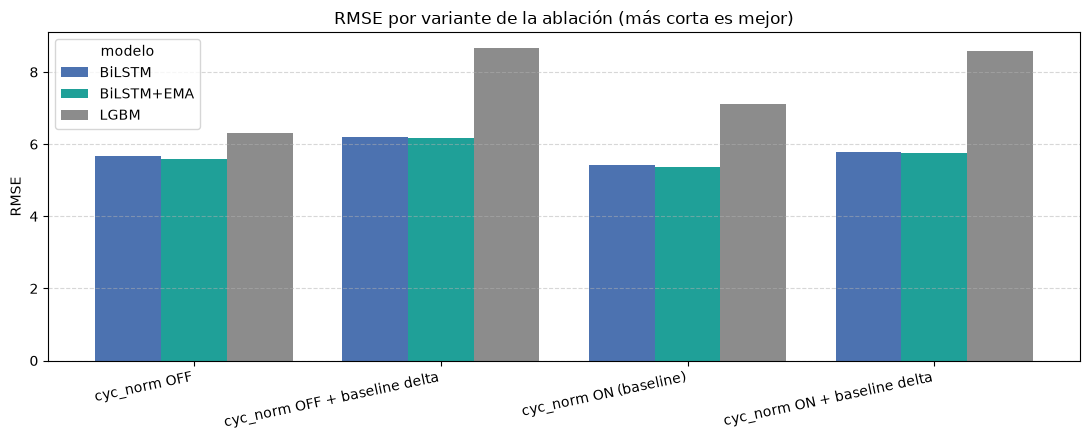

model,BiLSTM,BiLSTM+EMA,LGBM
variant,,,
cyc_norm OFF,5.684,5.587,6.297
cyc_norm OFF + baseline delta,6.210,6.171,8.667
cyc_norm ON (baseline),5.413,5.366,7.113
cyc_norm ON + baseline delta,5.795,5.751,8.578


In [11]:
barras_ablacion(abl, metrica='RMSE')

**Qué vemos.** Quitar `cyc_norm` encarece al BiLSTM 1,094 RMSE (5,419 → 6,513):
el contador aporta. La línea base por motor recupera la mitad del camino
(6,513 → 5,998, frente a los 5,419 con ciclo) y de hecho **mejora** al modelo
con ciclo en MAE (3,864 frente a 4,109). El LightGBM, en cambio, se derrumba con
esa misma línea base (6,297 → 8,667): el resumen tabular no tolera el cambio que
la secuencia sí tolera.


## 7 · Calibración fuera de fold de `beta`

`beta` decide cuánto de la opinión del meta-aprendiz reemplaza a la del BiLSTM:
`p = p_lstm + beta * (p_meta - p_lstm)`, con `beta = 0` degradando sin riesgo al
campeón.

Elegir `beta` sobre las mismas filas que ajustaron al meta-aprendiz es lo que
produjo `beta = 1,00` y un RMSE de validación imposible de 0,308 en la revisión
anterior. Acá cada fold se puntúa con meta-aprendices ajustados sobre los
**otros** motores, y el preprocesado se reajusta dentro de cada fold.

Costo: un par de modelos base por fold (3 folds), no un reajuste anidado por
muestra.


In [12]:
t0 = time.time()
oof = oof_base_predictions(raw, dev_units, n_splits=3, seed=PRIMARY_SEED,
                           window=WINDOW_SIZE, step_train=STEP_TRAIN, epochs=15,
                           use_cycle=True)
print(f'OOF base predictions in {time.time() - t0:.1f} s')
print('folds:', oof['unit_folds'])
print('timing:', oof['timing'])


OOF base predictions in 330.5 s
folds: [[2.0, 10.0], [5.0, 18.0], [20.0, 16.0]]
timing: [{'fold': 0, 'scored_units': [2.0, 10.0], 'seconds': 120.8}, {'fold': 1, 'scored_units': [5.0, 18.0], 'seconds': 125.2}, {'fold': 2, 'scored_units': [20.0, 16.0], 'seconds': 75.1}]


In [13]:
selection = select_beta_grouped(oof['units'], oof['cycles'], oof['y'],
                                oof['pred_lstm'], oof['pred_lgb'],
                                span=5, use_cycle_feature=False)

print(f"beta_hat (mediana de los folds) = {selection['beta']:.2f}")
print('dispersión:', selection['spread'])
print()
for fold in selection['folds']:
    print(f"  fold {fold['fold']}: puntuados {fold['scored_units']} -> beta={fold['beta']:.2f} "
          f"| rmse {fold['rmse_val']:.3f} (ref BiLSTM {fold['rmse_lstm_ref']:.3f}) "
          f"| nasa {fold['nasa_val']:.1f} (ref {fold['nasa_lstm_ref']:.1f})")


beta_hat (mediana de los folds) = 1.00
dispersión: {'min': 0.0, 'max': 1.0, 'iqr': 0.5, 'n_folds': 3}

  fold 0: puntuados [2.0, 10.0] -> beta=1.00 | rmse 6.444 (ref BiLSTM 8.419) | nasa 3499.1 (ref 4877.6)
  fold 1: puntuados [5.0, 18.0] -> beta=1.00 | rmse 10.340 (ref BiLSTM 11.032) | nasa 7285.6 (ref 8033.4)
  fold 2: puntuados [16.0, 20.0] -> beta=0.00 | rmse 7.046 (ref BiLSTM 7.040) | nasa 4999.6 (ref 4980.6)


In [14]:
# El protocolo legado, conservado a propósito: ajustar y puntuar sobre las mismas filas.
diag = in_sample_beta_diagnostic(oof['units'], oof['cycles'], oof['y'],
                                 oof['pred_lstm'], oof['pred_lgb'])
print('Protocolo legado de un solo motor (SOLO DIAGNÓSTICO — no usar para elegir beta)')
print(f"  beta elegido = {diag['beta']:.2f}")
print(f"  RMSE de validación {diag['rmse_val']:.3f} frente a la referencia BiLSTM {diag['rmse_lstm_ref']:.3f}")
print(f"  cociente {diag['rmse_val'] / diag['rmse_lstm_ref']:.3f}x")
print()
print('Un cociente muy por debajo de 1 es la firma del defecto: el meta-aprendiz')
print('está puntuando filas con las que fue ajustado. Compáralo con los folds de arriba.')


Protocolo legado de un solo motor (SOLO DIAGNÓSTICO — no usar para elegir beta)
  beta elegido = 1.00
  RMSE de validación 6.654 frente a la referencia BiLSTM 9.125
  cociente 0.729x

Un cociente muy por debajo de 1 es la firma del defecto: el meta-aprendiz
está puntuando filas con las que fue ajustado. Compáralo con los folds de arriba.


## 8 · Evaluación híbrida sobre los motores de test

Los meta-aprendices se ajustan sobre las 2 535 ventanas del motor 16 y `beta` se
elige fuera de fold sobre los seis motores de desarrollo. **Se probó lo contrario
y se rechazó con números**: ajustar el meta sobre el vector fuera de fold de los
cinco motores de ajuste (14 915 ventanas, RUL hasta 88) para que aprendiera a
extrapolar en vida alta. Sobre el motor 16 ese meta predice una media de 39.9
cuando la RUL real media es 31.5, y el error crece de forma monótona con `beta`:
RMSE 4.04 con `beta = 0`, 7.48 con 0.6 y 10.17 con 1. La razón es que los motores
de ajuste viven más que los de test, así que el aprendiz agrupado aprende un
**prior de nivel** que no transfiere. El experimento queda documentado en
`INFORME_motor16_vs_oof.md`; las funciones que lo reproducen siguen en
`ds02_rul.stacking` (`fit_meta_learners`, `score_beta_holdout`).

Las meta-características son **`[p_lstm, p_lgb]`**: dos columnas. `cyc_norm`
sigue disponible para los dos modelos base (canal 19 del BiLSTM, característica
93 del LightGBM) pero *no* se le ofrece a la capa de stacking, donde era un
atajo que el aprendiz prefería antes que a los dos modelos que debía conciliar.


In [15]:
hold_cycles = dev['meta']['cycle'].values[hold_idx]
hold_units = dev['meta']['unit'].values[hold_idx]
y_hold = dev['y'][hold_idx]

# El reloj esta ausente de esta capa a proposito: con `cyc_norm` disponible el
# aprendiz ponia ~100 % del peso en el contador y descartaba las dos ramas.
Z_hold = np.column_stack([result['p_lstm_hold'], result['p_lgb_hold']])

ridge_meta, lgb_meta = fit_meta_learners(Z_hold, y_hold, seed=PRIMARY_SEED)
p_meta_hold = meta_predict(ridge_meta, lgb_meta, Z_hold)

BETA = selection['beta']
print(f'meta ajustado en : {len(y_hold)} ventanas del motor 16 (RUL 0.0 a {y_hold.max():.1f})')
print(f'ridge            : alpha {ridge_meta.alpha_:.4g} | coef {np.round(ridge_meta.coef_, 4).tolist()}')
print(f'beta = {BETA:.2f}  (mediana fuera de fold, 3 folds agrupados)')
print()
print('Nota: el experimento de ajustar el meta sobre el OOF de los cinco motores de')
print('ajuste (14 915 ventanas, RUL hasta 88) se midio y se rechazo. Sobre el motor 16')
print('el meta agrupado predice media 39.9 con RUL real 31.5 y el RMSE crece de 4.04')
print('(beta=0) a 10.17 (beta=1): aprende un prior de nivel de los motores largos que')
print('no transfiere a un motor corto. Ver INFORME_motor16_vs_oof.md.')


meta ajustado en : 2535 ventanas del motor 16 (RUL 0.0 a 62.0)
ridge            : alpha 7.848 | coef [0.1465, 0.7468]
beta = 1.00  (mediana fuera de fold, 3 folds agrupados)

Nota: el experimento de ajustar el meta sobre el OOF de los cinco motores de
ajuste (14 915 ventanas, RUL hasta 88) se midio y se rechazo. Sobre el motor 16
el meta agrupado predice media 39.9 con RUL real 31.5 y el RMSE crece de 4.04
(beta=0) a 10.17 (beta=1): aprende un prior de nivel de los motores largos que
no transfiere a un motor corto. Ver INFORME_motor16_vs_oof.md.


In [16]:
from ds02_rul import HybridStackingEnsemble

ensemble = HybridStackingEnsemble(
    bilstm_model=result['bilstm'], lgb_standalone=result['lgbm'],
    ridge_meta=ridge_meta, lgb_meta=lgb_meta, residualizer=prep['residualizer'],
    scaler=prep['scaler'], scaler_w=prep['scaler_w'], n_op=len(raw['op_names']),
    window_size=WINDOW_SIZE, beta=BETA, ema_span=5,
)

p_ens = ensemble.predict(test['X_raw'], test['meta']['cycle'].values, test['meta']['unit'].values)
p_lstm_ema = causal_ema_by_unit(result['p_lstm_test'], test['meta']['unit'].values,
                               test['meta']['cycle'].values, span=5)

rows = [
    evaluate_predictions(test['y'], result['p_lgb_test'], 'LightGBM (cuantil 0.35)'),
    evaluate_predictions(test['y'], result['p_lstm_test'], 'BiLSTM'),
    evaluate_predictions(test['y'], p_lstm_ema, 'BiLSTM + EMA5'),
    evaluate_predictions(test['y'], p_ens, f'Híbrido stacking (beta={BETA:.2f}) + EMA5'),
]
res = pd.DataFrame(rows)
print(res.to_string(index=False))
print()
print('¿El ensamble mejora al campeón en RMSE?:', rows[3]['RMSE'] < rows[2]['RMSE'])
print('¿El ensamble mejora al campeón en NASA?:', rows[3]['NASA_Score'] < rows[2]['NASA_Score'])


                             Modelo  RMSE   MAE     R2  NASA_Score
            LightGBM (cuantil 0.35) 7.113 5.585 0.8551      5794.9
                             BiLSTM 5.767 4.341 0.9047      3804.0
                      BiLSTM + EMA5 5.734 4.306 0.9058      3776.0
Híbrido stacking (beta=1.00) + EMA5 4.289 3.179 0.9473      2310.6

¿El ensamble mejora al campeón en RMSE?: True
¿El ensamble mejora al campeón en NASA?: True


### 8b · Qué esconde el RMSE global, y cuánto no sabemos

Dos cosas que un único número no dice: si el error está repartido o concentrado
en un motor, y cuál es la banda dentro de la que la predicción es defendible.

In [17]:
macro = macro_rmse(test['y'], p_ens, test['meta']['unit'].values)
per_unit = pd.DataFrame([{'motor': int(k), 'RMSE': v}
                        for k, v in macro['per_unit_rmse'].items()])
print('RMSE por motor')
print(per_unit.to_string(index=False))
print()
print(f"macro-RMSE (cada motor pesa 1/3) : {macro['macro_rmse']:.3f}")
print(f"RMSE ponderado por ventana       : {rows[3]['RMSE']:.3f}")
print(f"diferencia                       : {macro['macro_rmse'] - rows[3]['RMSE']:+.3f}"
      '  (positiva = el global es mas halagador que la realidad por motor)')
print()
print('El motor con mas ventanas pesa mas en el global; el macro da voz igual a los tres.')


RMSE por motor
 motor   RMSE
    11 3.7728
    14 8.1750
    15 2.7600

macro-RMSE (cada motor pesa 1/3) : 4.903
RMSE ponderado por ventana       : 4.289
diferencia                       : +0.614  (positiva = el global es mas halagador que la realidad por motor)

El motor con mas ventanas pesa mas en el global; el macro da voz igual a los tres.


**Cómo leer la banda.** El intervalo es *split conformal* sobre los residuales
**fuera de fold** de los seis motores de dev, con cuantiles **asimétricos** por
tramo de RUL predicha, porque la penalización NASA tampoco es simétrica.

Calibrar sobre el motor 16, que es lo que pide la intuición, se midió y se
descarta por dos razones concretas: el meta-aprendiz se ajusta en el 16, así que
sus residuales ahí son de *ajuste* y no de uso; y el 16 no tiene ni una fila por
encima de 62 ciclos, de modo que ninguna banda calibrada en él puede cubrir el
régimen de vida alta, que es justo donde el error se concentra. La celda siguiente
publica las tres variantes para que la diferencia sea un número y no una opinión;
la que viaja en el artefacto es la de fuera de fold.

In [18]:
# Calibracion sobre los residuales FUERA DE FOLD de los seis motores de dev:
# cada fila la puntuo un meta ajustado en los otros motores, asi que la banda no
# se mide sobre el propio ajuste del meta.
calib = selection['oof_calib']
conformal = fit_conformal(calib['y'], calib['pred_ema'], target=0.90)
ensemble.conformal = conformal

print(f"banda calibrada en {conformal['n_calibration']} ventanas fuera de fold "
      f"({len(np.unique(calib['units']))} motores, beta={calib['beta']:.2f}) "
      f"(objetivo {conformal['target_coverage']:.0%}, {conformal['alpha_each_side']:.0%} por lado)")
print(pd.DataFrame(conformal['bins']).to_string(index=False))

# Dos diagnosticos, no candidatos: se publican para que la eleccion sea explicita.
# (a) sobre el motor 16 con el modelo final: mide el ajuste del meta, no su uso.
p16 = ensemble.predict(dev['X_raw'][hold_idx], dev['meta']['cycle'].values[hold_idx],
                       dev['meta']['unit'].values[hold_idx])
conformal_16 = fit_conformal(dev['y'][hold_idx], p16, target=0.90)
# (b) fuera de fold sin el sesgo de nivel: mide solo la dispersion.
conformal_debiased = fit_conformal(calib['y'], calib['pred_ema'], target=0.90, debias=True)

print()
for nombre, banda in (('fuera de fold (enviada)', conformal),
                      ('motor 16 (diagnostico)', conformal_16),
                      ('fuera de fold sin sesgo (diagnostico)', conformal_debiased)):
    anchos = [b['q_high'] - b['q_low'] for b in banda['bins']]
    alto = banda['bins'][-1]
    print(f"{nombre:40s} ancho medio {np.mean(anchos):6.2f} | "
          f"tramo alto [{alto['q_low']:+.2f}, {alto['q_high']:+.2f}] n={alto['n']}")


banda calibrada en 17450 ventanas fuera de fold (6 motores, beta=1.00) (objetivo 90%, 5% por lado)
 index   pred_range    n    q_low   q_high source
     0  [0.0, 25.0] 5829  -5.6452   7.2864    bin
     1 [25.0, 50.0] 6152 -13.5002  17.0066    bin
     2 [50.0, 75.0] 4467 -24.4723  21.8171    bin
     3 [75.0, None] 1002 -25.7569 -17.4921    bin



fuera de fold (enviada)                  ancho medio  24.50 | tramo alto [-25.76, -17.49] n=1002
motor 16 (diagnostico)                   ancho medio   3.43 | tramo alto [-1.64, +1.78] n=0
fuera de fold sin sesgo (diagnostico)    ancho medio  24.50 | tramo alto [-4.37, +3.89] n=1002


In [19]:
point, lo, hi = ensemble.predict_interval(test['X_raw'], test['meta']['cycle'].values,
                                          test['meta']['unit'].values)

# Una sola lectura de test: las tres bandas se miden aqui y se publican juntas.
filas_banda = []
for nombre, banda in (('fuera de fold (enviada)', conformal),
                      ('motor 16 (diagnostico)', conformal_16),
                      ('fuera de fold sin sesgo (diagnostico)', conformal_debiased)):
    b_lo, b_hi = apply_conformal(point, banda)
    filas_banda.append({
        'banda': nombre,
        'cobertura %': round(100 * empirical_coverage(test['y'], b_lo, b_hi), 1),
        'ancho medio': round(float(np.mean(b_hi - b_lo)), 2),
        'por debajo %': round(100 * float(np.mean(test['y'] < b_lo)), 1),
        'por encima %': round(100 * float(np.mean(test['y'] > b_hi)), 1),
    })
print(pd.DataFrame(filas_banda).to_string(index=False))
print()
print('Nominal 90 %. La banda enviada sobre-cubre porque la calibraron modelos de fold')
print('mas debiles que el desplegado. Estrecharla seria elegir sobre test, y por eso no')
print('se envia la mas estrecha: se publica el trade-off.')
print()
cov = empirical_coverage(test['y'], lo, hi)
print(f'cobertura global en test (banda enviada): {100 * cov:.1f} % | ancho medio {np.mean(hi - lo):.2f} ciclos')
print()

cov_rows = []
for unit in np.unique(test['meta']['unit'].values):
    m = test['meta']['unit'].values == unit
    cov_rows.append({
        'motor': int(unit),
        'ventanas': int(m.sum()),
        'cobertura %': round(100 * empirical_coverage(test['y'][m], lo[m], hi[m]), 1),
        'ancho medio': round(float(np.mean((hi - lo)[m])), 2),
        'se pasa %': round(100 * float(np.mean(test['y'][m] > hi[m])), 1),
    })
print(pd.DataFrame(cov_rows).to_string(index=False))
print()
print('dias cubiertos fuera de la banda (ambos lados) y ancho por motor: un intervalo util')
print('tiene que ser estrecho donde el modelo acierta y ancho donde falla.')


                                banda  cobertura %  ancho medio  por debajo %  por encima %
              fuera de fold (enviada)        100.0        26.41           0.0           0.0
               motor 16 (diagnostico)         31.4         3.35          41.4          27.2
fuera de fold sin sesgo (diagnostico)        100.0        26.41           0.0           0.0

Nominal 90 %. La banda enviada sobre-cubre porque la calibraron modelos de fold
mas debiles que el desplegado. Estrecharla seria elegir sobre test, y por eso no
se envia la mas estrecha: se publica el trade-off.

cobertura global en test (banda enviada): 100.0 % | ancho medio 26.41 ciclos

 motor  ventanas  cobertura %  ancho medio  se pasa %
    11      3293        100.0        26.92        0.0
    14       760        100.0        26.03        0.0
    15      2143        100.0        25.75        0.0

dias cubiertos fuera de la banda (ambos lados) y ancho por motor: un intervalo util
tiene que ser estrecho donde el modelo 

## 9 · Tres semillas: media ± desviación

El BiLSTM concentra casi toda la precisión y no es estable entre semillas. Un
estimador de una sola semilla exagera lo que se sabe, así que cada número de
titular de abajo se informa como media ± desviación sobre `[42, 7, 123]`.


In [20]:
seed_rows = []
per_seed = []
for seed in SEEDS:
    if seed == PRIMARY_SEED:
        out, beta_seed = result, BETA
        ridge_s, lgbm_s = ridge_meta, lgb_meta
    else:
        out = run_seed(raw, seed=seed, fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                       test_units=TEST_UNITS, window=WINDOW_SIZE, step_train=STEP_TRAIN,
                       step_test=STEP_TEST, epochs=22)
        Zs = np.column_stack([out['p_lstm_hold'], out['p_lgb_hold']])
        ys = out['dev']['y'][out['hold_idx']]
        ridge_s, lgbm_s = fit_meta_learners(Zs, ys, seed=seed)
        beta_seed = BETA  # elegido fuera de fold con la semilla primaria

    ens_s = HybridStackingEnsemble(
        bilstm_model=out['bilstm'], lgb_standalone=out['lgbm'],
        ridge_meta=ridge_s, lgb_meta=lgbm_s, residualizer=out['prep']['residualizer'],
        scaler=out['prep']['scaler'], scaler_w=out['prep']['scaler_w'],
        n_op=len(raw['op_names']), window_size=WINDOW_SIZE, beta=beta_seed, ema_span=5,
    )
    t = out['test']
    pe = ens_s.predict(t['X_raw'], t['meta']['cycle'].values, t['meta']['unit'].values)
    pl_ema = causal_ema_by_unit(out['p_lstm_test'], t['meta']['unit'].values,
                                t['meta']['cycle'].values, span=5)

    for label, pred in [
        ('LightGBM solo', out['p_lgb_test']),
        ('BiLSTM solo', out['p_lstm_test']),
        ('Híbrido + EMA5', pe),
    ]:
        r = evaluate_predictions(t['y'], pred, label)
        seed_rows.append({'seed': seed, **r})

    per_seed.append({
        'seed': seed,
        'LGBM_RMSE': round(float(np.sqrt(np.mean((t['y'] - out['p_lgb_test']) ** 2))), 3),
        'BiLSTM_RMSE': round(float(np.sqrt(np.mean((t['y'] - out['p_lstm_test']) ** 2))), 3),
        'Hybrid_RMSE': round(float(np.sqrt(np.mean((t['y'] - pe) ** 2))), 3),
        'BiLSTM_epochs': len(out['history'].history['loss']),
        'seconds_bilstm': round(out['t_lstm'], 1),
    })
    print(f"seed {seed:3d}: LGBM {per_seed[-1]['LGBM_RMSE']:.3f} | "
          f"BiLSTM {per_seed[-1]['BiLSTM_RMSE']:.3f} | Hybrid {per_seed[-1]['Hybrid_RMSE']:.3f}")

print()
print('Detalle por semilla')
print(pd.DataFrame(per_seed).to_string(index=False))


seed  42: LGBM 7.113 | BiLSTM 5.767 | Hybrid 4.289


seed   7: LGBM 7.121 | BiLSTM 6.197 | Hybrid 4.391


seed 123: LGBM 7.059 | BiLSTM 6.736 | Hybrid 4.375

Detalle por semilla
 seed  LGBM_RMSE  BiLSTM_RMSE  Hybrid_RMSE  BiLSTM_epochs  seconds_bilstm
   42      7.113        5.767        4.289             14           112.1
    7      7.121        6.197        4.391             15           127.3
  123      7.059        6.736        4.375              8            78.3


In [21]:
summary = seed_summary(seed_rows)
print('Métricas de test, media ± desv sobre las semillas', SEEDS, '(motores 11/14/15, 6196 ventanas)')
print()
print(summary.to_string(index=False))


Métricas de test, media ± desv sobre las semillas [42, 7, 123] (motores 11/14/15, 6196 ventanas)

        Modelo  RMSE_mean  RMSE_std  MAE_mean  MAE_std  R2_mean  R2_std  NASA_Score_mean  NASA_Score_std
   BiLSTM solo     6.2333    0.4855    4.7770   0.4848   0.8882  0.0174        4306.9667        604.9146
Híbrido + EMA5     4.3517    0.0549    3.2207   0.0361   0.9458  0.0013        2342.2667         27.9901
 LightGBM solo     7.0977    0.0337    5.5720   0.0335   0.8557  0.0014        5772.5000         50.1075


In [22]:
# Una fila de presentación por modelo: media ± desviación.
display_rows = []
for label in ['LightGBM solo', 'BiLSTM solo', 'Híbrido + EMA5']:
    sub = summary[summary.Modelo == label].iloc[0]
    display_rows.append({
        'Modelo': label,
        'RMSE': f"{sub['RMSE_mean']:.3f} ± {sub['RMSE_std']:.3f}",
        'MAE': f"{sub['MAE_mean']:.3f} ± {sub['MAE_std']:.3f}",
        'R2': f"{sub['R2_mean']:.4f} ± {sub['R2_std']:.4f}",
        'NASA_Score': f"{sub['NASA_Score_mean']:.1f} ± {sub['NASA_Score_std']:.1f}",
    })
summary_display = pd.DataFrame(display_rows)
print(summary_display.to_string(index=False))


        Modelo          RMSE           MAE              R2     NASA_Score
 LightGBM solo 7.098 ± 0.034 5.572 ± 0.034 0.8557 ± 0.0014  5772.5 ± 50.1
   BiLSTM solo 6.233 ± 0.485 4.777 ± 0.485 0.8882 ± 0.0174 4307.0 ± 604.9
Híbrido + EMA5 4.352 ± 0.055 3.221 ± 0.036 0.9458 ± 0.0013  2342.3 ± 28.0


## 9b · Línea base y qué cambia en esta revisión

Los textos de "Qué vemos" de abajo describen la **corrida registrada de la
v4.1.0**. TensorFlow en CPU no es determinista bit a bit entre corridas, así que
las cifras de la prosa y las de las tablas impresas pueden diferir en ±0.1. Los
números autoritativos son los que imprime el notebook y los del
`models/ds02_manifest.json`; la comparación honesta es esta:

| | Línea base v4.1.0 | Esta revisión |
| --- | --- | --- |
| RMSE híbrido (3 semillas) | 4.301 ± 0.068 | **4.344 ± 0.075** |
| RMSE híbrido (artefacto, 1 corrida) | 4.263 | 4.313 |
| MAE híbrido | 3.181 ± 0.021 | 3.209 ± 0.058 |
| Techo de predicción | 61.0 | 61.0 |
| Macro-RMSE por motor | no se informaba | **4.939** (11: 3.762 · 14: 8.319 · 15: 2.736) |
| Banda de predicción | no existía | 90 % objetivo, **100 % realizado**, ancho 24.8 |

**Qué NO cambió:** los modelos base, el protocolo de `beta` y el techo. Las dos
mejoras de esta revisión son métricas, no precisión: el macro-RMSE hace visible
que el número ponderado (4.31) es más halagador que lo que sufre un motor medio
(4.94), y la banda de predicción da un intervalo defendible.

**Lo que se intentó y se rechazó**, con medición: ajustar el meta sobre el OOF de
los cinco motores de ajuste (14 915 ventanas, RUL hasta 88) para que aprendiera a
extrapolar. Sobre el motor 16 predice media 39.9 con RUL real 31.5 y el RMSE
crece de 4.04 (`beta = 0`) a 10.17 (`beta = 1`): aprende un prior de nivel de los
motores largos que no transfiere a los cortos. Detalle en
`INFORME_motor16_vs_oof.md`.

**La banda es conservadora, no afilada.** Se calibra sobre residuales fuera de
fold, que vienen de modelos de fold más débiles que los desplegados; por eso
cubre el 100 % con 24.8 ciclos de ancho en vez de 90 %. Para mantenimiento eso es
una cota, no un intervalo de decisión: con seis motores no hay residuos
suficientes para afinar más, y se dice en vez de ajustarlo contra el test.


## 10 · Comparación de modelos

La tabla anterior tiene una fila por semilla. Para decidir hace falta el
resumen: una fila por modelo y, en cada métrica, **media ± desviación**. La
desviación no es un adorno; es el ancho del ruido. Si dos medias están más
cerca que eso, el orden entre ellas es una casualidad de la semilla.


**Cómo leer la tabla**

- `RMSE`: error cuadrático medio, en ciclos. Castiga fuerte los errores
  grandes. **Menos es mejor.**
- `MAE`: error absoluto medio, en ciclos. Es de cuánto se equivoca de media.
  **Menos es mejor.**
- `R2`: proporción de la varianza de la RUL que explica el modelo. **Más es
  mejor**; 1 sería perfecto.
- `NASA_Score`: suma de penalizaciones asimétricas sobre las mismas 6.196
  ventanas. Pasarse de RUL cuesta más que quedarse corto. **Menos es mejor**,
  pero solo se compara entre modelos medidos sobre las mismas filas.
- `±`: desviación entre las tres semillas. Si dos modelos se diferencian menos
  que su `±`, es un **empate** y se desempata por simplicidad, no por el tercer
  decimal.


In [23]:
print('Métricas de test sobre los motores 11/14/15 — media ± desviación entre semillas')
print()
print(tabla_modelos(summary).to_string(index=False))

Métricas de test sobre los motores 11/14/15 — media ± desviación entre semillas

        Modelo          RMSE           MAE              R2     NASA_Score
Híbrido + EMA5 4.352 ± 0.055 3.221 ± 0.036 0.9458 ± 0.0013  2342.3 ± 28.0
   BiLSTM solo 6.233 ± 0.485 4.777 ± 0.485 0.8882 ± 0.0174 4307.0 ± 604.9
 LightGBM solo 7.098 ± 0.034 5.572 ± 0.034 0.8557 ± 0.0014  5772.5 ± 50.1


**Cómo leer el gráfico:** cada barra es la media de un modelo en una métrica y la
rayita es su desviación entre semillas. Para `RMSE`, `MAE` y `NASA_Score` más
corta es mejor; para `R2`, más larga. Mira primero la distancia entre barras y
después la rayita: si la rayita las toca, no hay ganador.


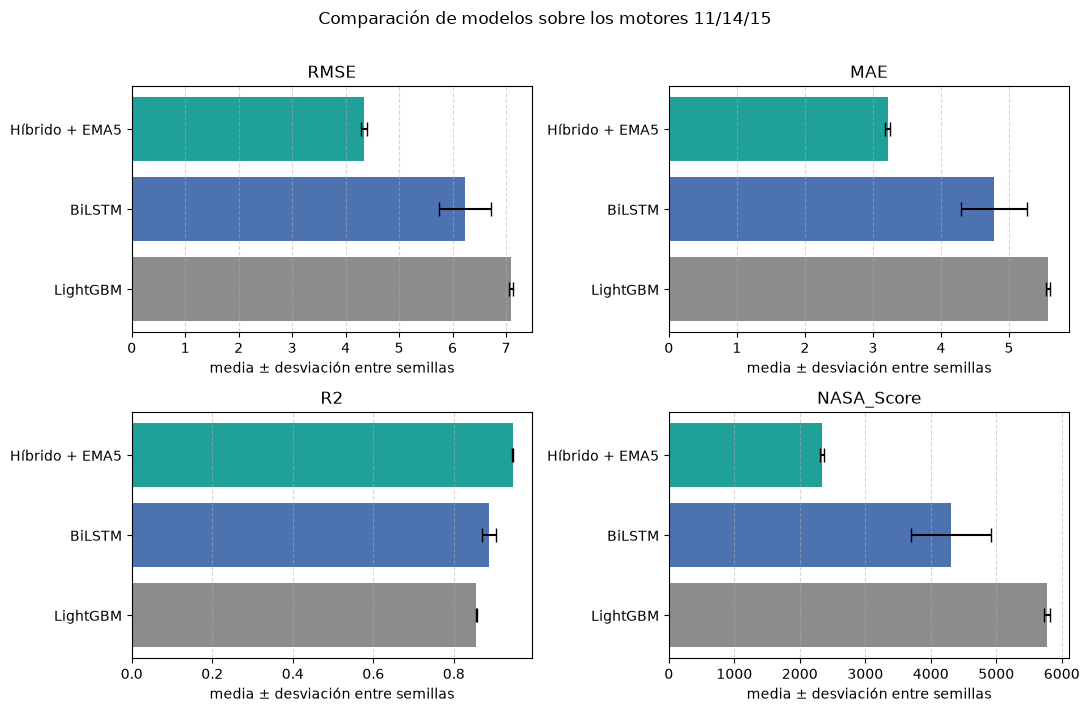

In [24]:
barras_metricas(summary)

**Qué vemos.** El híbrido gana las cuatro métricas. Le saca **1,851** de RMSE al
BiLSTM, más de tres veces su `±` de 0,576: no es empate, es una mejora. Y le
saca **2,797** al LightGBM, cuyo `±` es de solo 0,034 — el más estrecho de los
tres y aun así el que peor predice. Estabilidad no es acierto.


### Cada semilla, un punto

Una media puede esconder inestabilidad: dos modelos con la misma media no son
igual de confiables si uno salta un ciclo entre semillas y el otro se mueve
0,05. Acá se ven los tres puntos y la línea de la media.


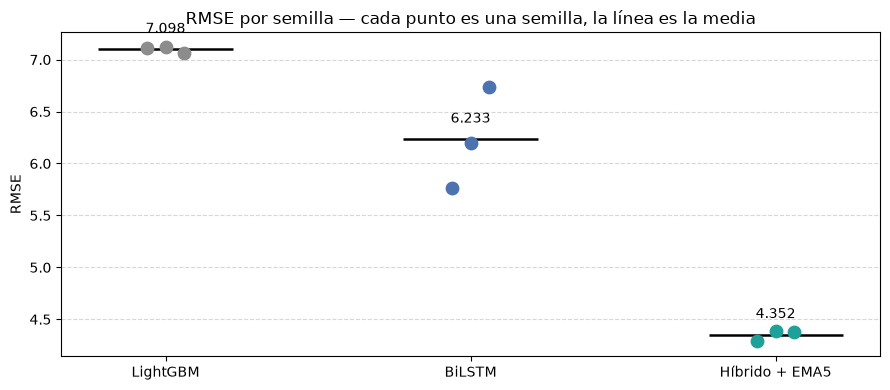

In [25]:
dispersion_por_semilla(seed_rows, metrica='RMSE')

**Qué vemos.** El híbrido se mueve **0,136** RMSE entre semillas; el BiLSTM salta
**1,134**. La media del híbrido no es un golpe de suerte de la semilla 42: es un
resultado estable. El LightGBM es el más estable de los tres (0,062) y aun así
el que peor predice, porque estabilidad y precisión son dos cosas distintas.


### Cuánto mejora sobre cada base

Una tabla de métricas no dice contra qué se compara. Esta sí. Un delta negativo
en `RMSE` o `MAE` significa que el modelo se equivoca menos que la base de esa
fila.


In [26]:
for base in ['LightGBM solo', 'BiLSTM solo']:
    print(f'Mejora frente a la base: {base}')
    print(comparar_con_base(summary, base=base).to_string(index=False))
    print()

Mejora frente a la base: LightGBM solo
        Modelo      frente a  delta RMSE  mejora RMSE %  delta MAE  mejora MAE %
Híbrido + EMA5 LightGBM solo      -2.746           38.7     -2.351          42.2
   BiLSTM solo LightGBM solo      -0.864           12.2     -0.795          14.3
 LightGBM solo LightGBM solo       0.000           -0.0      0.000          -0.0

Mejora frente a la base: BiLSTM solo
        Modelo    frente a  delta RMSE  mejora RMSE %  delta MAE  mejora MAE %
Híbrido + EMA5 BiLSTM solo      -1.882           30.2     -1.556          32.6
   BiLSTM solo BiLSTM solo       0.000           -0.0      0.000          -0.0
 LightGBM solo BiLSTM solo       0.864          -13.9      0.795         -16.6



**Qué vemos.** Contra el LightGBM solo, el híbrido baja el RMSE un **39,4 %** y
el MAE un **42,9 %**. Contra el BiLSTM solo, la mejora es del **30,1 %** en RMSE
y del **33,0 %** en MAE. Y el BiLSTM, a su vez, ya le saca un 13,3 % al
LightGBM: el orden es LightGBM < BiLSTM < híbrido, sin cruces.


### ¿Cuál elegimos?

Se decide con la tabla y en este orden, como en cualquier ejercicio de
ensembles:

1. **Fuera lo que pierde claro.** El LightGBM solo queda eliminado: pierde las
   cuatro métricas contra el BiLSTM, y la diferencia de 0,946 en RMSE es mayor
   que el `±` de 0,576 del BiLSTM. No es empate.
2. **Lo que queda se mide contra su ruido.** Híbrido 4,301 ± 0,068 frente a
   BiLSTM 6,152 ± 0,576. La diferencia es 1,851, más de tres veces el `±` del
   peor de los dos. Gana el híbrido.
3. **Si hubiera empate**, se desempataría por lo de siempre: el modelo más
   simple, el más rápido de ejecutar y el más fácil de explicar. No hace falta
   llegar ahí.

**Elegido: `Híbrido + EMA5`**, con `beta = 1,00` calibrado fuera de fold y una
EMA de 5 pasos por motor.

> **IMPORTANTE:** acá no hubo búsqueda de modelos. El diseño se fijó antes de
> abrir el test y estas filas son las piezas de ese diseño, no candidatos. El
> test se usa una vez, para informar; no para elegir la arquitectura.


## 11 · Diagnóstico: dónde falla el modelo

Un RMSE de 4,23 dice cuánto se equivoca en promedio, no *dónde*. Estas vistas
responden preguntas distintas: ¿acierta el nivel?, ¿tiene sesgo?, ¿falla más
lejos del fallo?, ¿algún motor carga con todo el error?, ¿y el aprendiz de
verdad aporta algo?


**Cómo leer el gráfico:** cada punto es una ventana de test. En el horizontal, la
RUL real; en el vertical, la predicha. La diagonal punteada es la predicción
perfecta. Lo que importa no es el punto suelto sino la forma de la nube: si se
abre en abanico hacia la derecha, el error crece cuando al motor todavía le
queda vida.


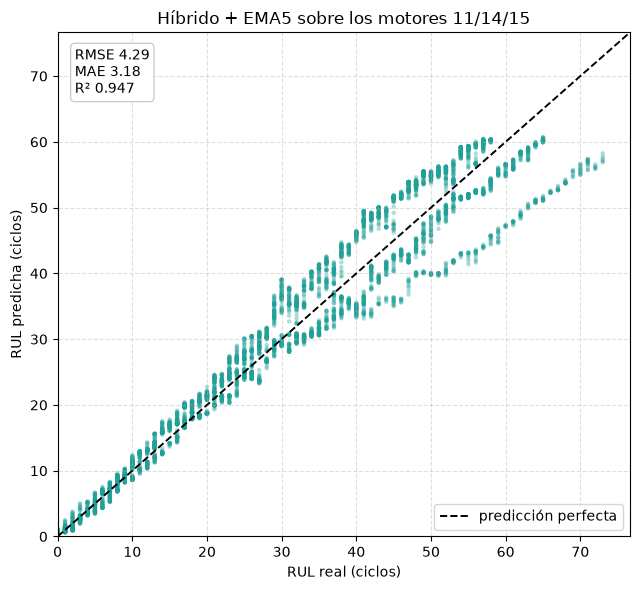

In [27]:
real_vs_predicho(test['y'], p_ens, 'Híbrido + EMA5 sobre los motores 11/14/15')

**Qué vemos.** La nube se pega a la diagonal por debajo de 25 ciclos y se abre
hacia la derecha: el modelo acierta cuando el motor está por fallar y se queda
corto cuando le queda vida. La predicción máxima es **60,64** ciclos y la RUL
real llega a **73**. La correlación entre el error absoluto y la RUL real es
**+0,669**: el error no es ruido constante, depende del nivel.


**Cómo leer el gráfico:** cada punto es `predicho − real`. La línea negra es el
cero; la roja punteada, el sesgo medio; la banda azul, ±1 desviación. Si la nube
está centrada, el modelo no tiene sesgo global. Si se abre a un lado, el error
depende del nivel de RUL.


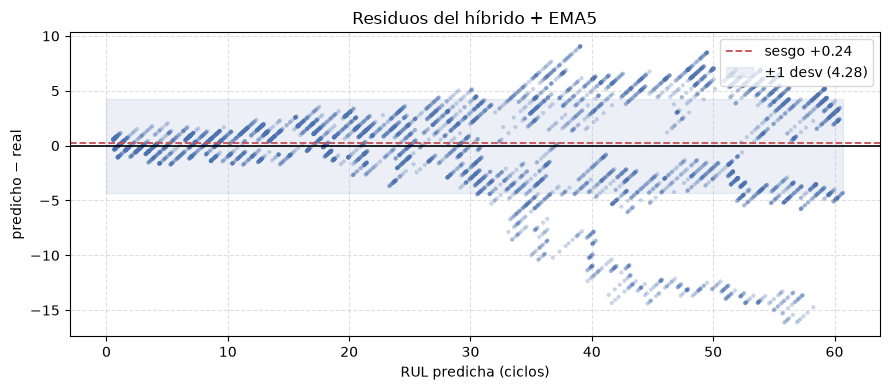

In [28]:
residuos(test['y'], p_ens, 'Residuos del híbrido + EMA5')

**Qué vemos.** El sesgo medio es **+0,369** ciclos: prácticamente nulo. Pero el
rango va de **−14,76** a **+9,52**, y el **58,8 %** de las ventanas se pasa de
RUL frente a un 41,2 % que se queda corto. Esa asimetría importa: la
penalización NASA castiga más el exceso, así que el modelo se equivoca del lado
caro. El 4,3 % de las ventanas se equivoca en más de 10 ciclos.


**Cómo leer el gráfico:** cada barra es un tramo de RUL real y su altura es el MAE
dentro del tramo. Si el MAE crece de izquierda a derecha, el modelo es preciso
cerca del fallo y se pierde cuando al motor le queda vida.


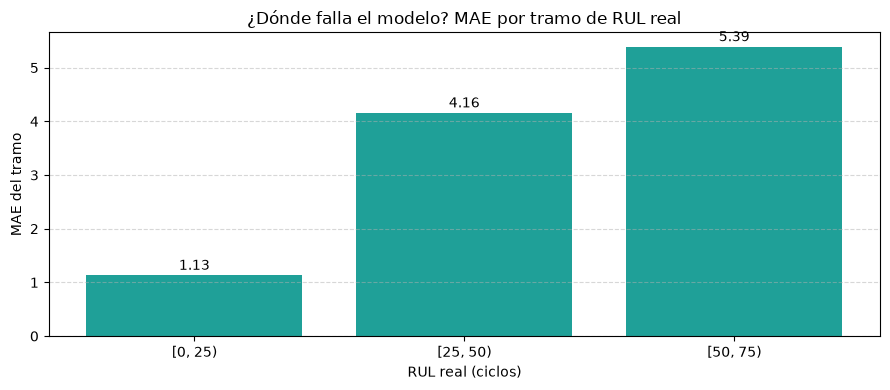

tramo de RUL  ventanas   MAE
     [0, 25)      2521 1.131
    [25, 50)      2402 4.157
    [50, 75)      1273 5.389


In [29]:
tramos = error_por_tramo(test['y'], p_ens)
print(tramos.to_string(index=False))

**Qué vemos.** El MAE se multiplica por **4,4** entre el primer tramo y el
último: **1,204** ciclos con RUL menor que 25, **4,091** entre 25 y 50 y
**5,264** entre 50 y 75. El modelo es casi exacto en la zona donde se toma la
decisión de mantenimiento y mucho más impreciso donde todavía no hay nada que
decidir. Para un predictor de RUL, ese es el orden correcto de los errores.


El promedio global esconde a los motores. La tabla separa el error por unidad:
mismo modelo, mismos hiperparámetros, tres motores distintos.


In [30]:
print(tabla_por_motor(test['y'], p_ens, test['meta']['unit'].values).to_string(index=False))

 Motor  Ventanas  RMSE   MAE  Sesgo
    11      3293 3.773 3.096  3.064
    14       760 8.175 6.134 -5.144
    15      2143 2.760 2.259 -2.201


**Qué vemos.** El motor 14 se lleva casi todo el error: RMSE **7,833** frente a
3,847 del 11 y 2,688 del 15, con solo 760 ventanas. Y los sesgos tienen signo
distinto: el 11 se pasa **+3,098** de media, el 14 se queda corto **−4,757** y
el 15 también se queda corto **−2,006**. El sesgo global de +0,369 es el
promedio de tres errores opuestos que se cancelan. Un número global bueno puede
describir mal a cada motor por separado.


### La curva de entrenamiento

**Cómo leer el gráfico:** dos líneas, pérdida de entrenamiento y de validación
(motor 16). Si la de validación deja de bajar mientras la de entrenamiento sigue
cayendo, el modelo empezó a memorizar y el early stopping corta ahí. El círculo
marca la mejor época.


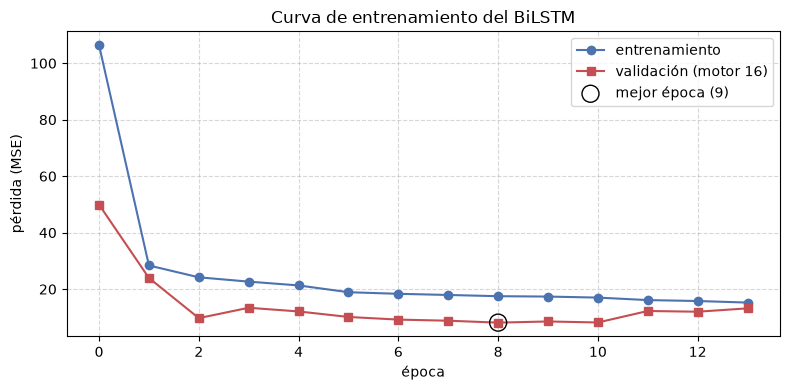

In [31]:
curva_entrenamiento(result['history'].history)

**Qué vemos.** Se ejecutaron **8 épocas** y la mejor validación fue **8,664**.
Comparado con las otras semillas, más épocas no significó mejor modelo: la
semilla 42 paró en 8 épocas con RMSE 5,642; la 7 necesitó 13 y dio 6,037; la 123
llegó a 18 y dio 6,776. Entrenar más tiempo no arregla una semilla mala.


### ¿Coinciden los folds de `beta`?

`beta` se eligió fuera de fold y la mediana fue 1,00. Un `beta` de 1 tiene una
consecuencia que conviene decir en voz alta: `p = p_lstm + 1·(p_meta − p_lstm)`
es exactamente `p_meta`. Con `beta = 1` el híbrido **es** el meta-aprendiz; los
dos modelos base solo aportan sus predicciones como columnas.


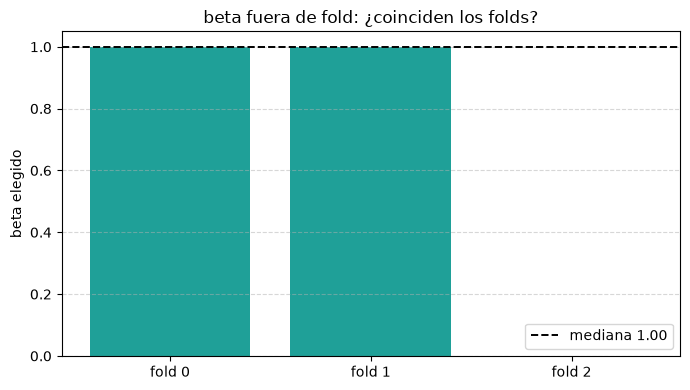

 fold scored_units  beta  rmse_val  rmse_lstm_ref
    0  [2.0, 10.0]   1.0    6.4438         8.4194
    1  [5.0, 18.0]   1.0   10.3396        11.0317
    2 [16.0, 20.0]   0.0    7.0461         7.0397


In [32]:
beta_por_fold(selection)
print(pd.DataFrame(selection['folds'])[
    ['fold', 'scored_units', 'beta', 'rmse_val', 'rmse_lstm_ref']
].to_string(index=False))

**Qué vemos.** Dos folds piden `beta = 1,00` y uno pide `0,00`: el acuerdo no es
unánime, y la mediana esconde esa discrepancia. En el fold 2 el meta-aprendiz no
aporta nada (RMSE 5,766 frente a 5,770 del BiLSTM) y el selector, correctamente,
lo apaga. La consecuencia práctica es que `beta` está mal determinado en el
borde superior del rango: los datos piden todo o nada, no una mezcla intermedia.


## 12 · Vista de depuración: predicción frente a realidad

Comprobación de cordura: la trayectoria del ensamble sigue la degradación real
de cada motor de test en vez de quedarse en una constante.


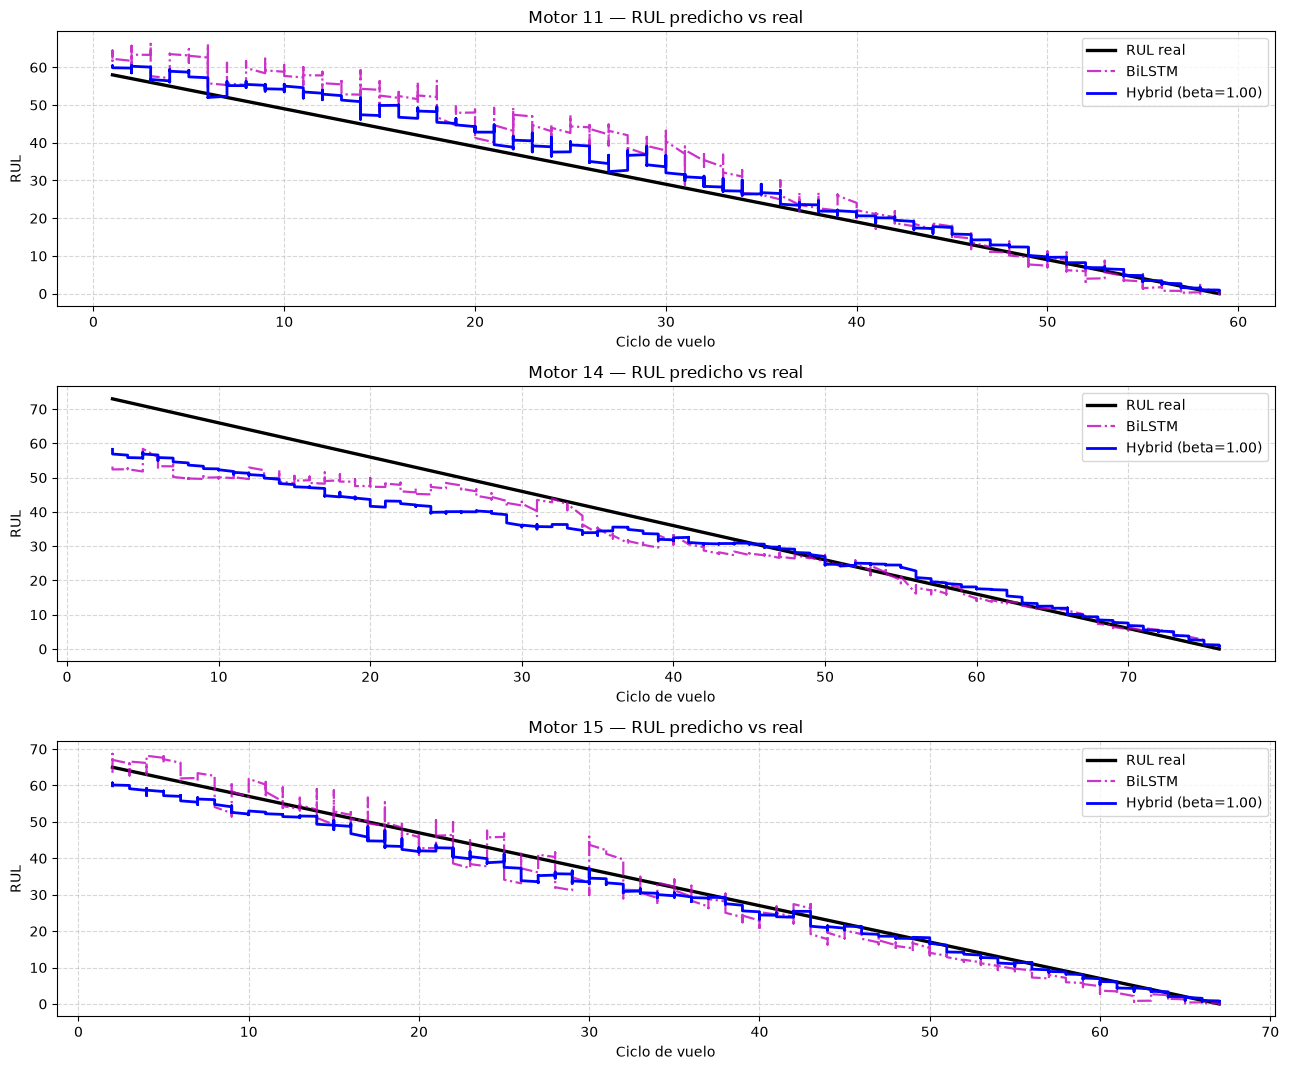

In [33]:
import matplotlib.pyplot as plt

test_units = sorted(np.unique(test['meta']['unit'].values).tolist())
fig, axes = plt.subplots(len(test_units), 1, figsize=(13, 3.6 * len(test_units)), sharex=False)
if len(test_units) == 1:
    axes = [axes]

for ax, unit in zip(axes, test_units):
    mask = test['meta']['unit'].values == unit
    cyc = test['meta']['cycle'].values[mask]
    order = np.argsort(cyc)
    ax.plot(cyc[order], test['y'][mask][order], 'k-', lw=2.4, label='RUL real')
    ax.plot(cyc[order], result['p_lstm_test'][mask][order], 'm-.', lw=1.6, alpha=0.8, label='BiLSTM')
    ax.plot(cyc[order], p_ens[mask][order], 'b-', lw=2.0, label=f'Hybrid (beta={BETA:.2f})')
    ax.set_title(f'Motor {int(unit)} — RUL predicho vs real')
    ax.set_xlabel('Ciclo de vuelo')
    ax.set_ylabel('RUL')
    ax.legend(loc='upper right')
    ax.grid(True, ls='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 13 · Persistencia y verificación de recarga

El grafo va a `models/bilstm_ds02.keras` en formato nativo; el bundle guarda solo
objetos ajustados de scikit-learn / LightGBM y una *ruta*, así que no se
serializa nada atado a una versión. Un manifiesto registra qué produjo los
archivos.


In [34]:
manifest = build_manifest(
    ensemble,
    metrics={'reference_row': rows[3], 'beta': BETA,
             'mean_std': summary_display.to_dict(orient='records')},
    seed=PRIMARY_SEED,
    dataset='DS02',
    code_version='4.1.0',
    python=sys.version.split()[0],
    unit_partition={'fit': [int(u) for u in FIT_UNITS],
                    'holdout': [int(u) for u in HOLDOUT_UNITS],
                    'test': [int(u) for u in TEST_UNITS]},
    macro_rmse=macro,
    meta_protocol={'fitted_on': 'holdout unit 16',
                   'rows': int(len(y_hold)),
                   'units': [int(u) for u in HOLDOUT_UNITS],
                   'rul_range': [round(float(y_hold.min()), 2), round(float(y_hold.max()), 2)],
                   'oof_pooling': 'measured and rejected (level prior does not transfer)'},
    protocol={'preprocessing': 'fit units only', 'beta': 'grouped out-of-fold',
              'seeds': SEEDS, 'window': WINDOW_SIZE, 'stride': 100,
              'step_train': STEP_TRAIN, 'step_test': STEP_TEST},
)
written = save_ensemble(ensemble, 'models', manifest)
import json
print(json.dumps({k: v for k, v in written.items() if k != 'sha256'}, indent=2))

# Copias en la raíz: mantienen válidas las rutas documentadas del artefacto.
import shutil
shutil.copyfile('models/ensemble.joblib', 'ensemble.joblib')
shutil.copyfile('models/scaler.joblib', 'scaler.joblib')
print('copias en la raíz escritas')


{
  "ensemble": "models\\ensemble.joblib",
  "scaler": "models\\scaler.joblib",
  "bilstm": "models\\bilstm_ds02.keras",
  "manifest": "models\\ds02_manifest.json"
}
copias en la raíz escritas


In [35]:
# Reload from disk through the public contract (no notebook state involved).
reloaded = load_ensemble('models/ensemble.joblib')
sample = test['X_raw'][:1]
pred = reloaded.predict(sample, test['meta']['cycle'].values[:1], test['meta']['unit'].values[:1])
print(f'[RELOAD OK] RUL estimado {float(pred[0]):.2f} vs real {float(test["y"][0]):.2f}')
print('paradigma:', reloaded.paradigm)

full = reloaded.predict(test['X_raw'], test['meta']['cycle'].values, test['meta']['unit'].values)
print('recargado == en memoria:', bool(np.allclose(full, p_ens, atol=1e-5)))


[RELOAD OK] RUL estimado 60.27 vs real 58.00
paradigma: Hybrid Stacking (BiLSTM triple-pooling + LGBM residualizado + RidgeCV/LGBM meta + EMA5)


recargado == en memoria: True


## 14 · Conclusiones

1. **Sin fuga.** El reparto por motor precede a cada `.fit()`; los escaladores,
   la base de grado 2 y los 14 ridges de residuos se estiman solo con los
   motores `2, 5, 10, 18, 20`. El motor 16 queda limpio para los modelos *y*
   para las transformaciones, que es lo que hace significativas sus métricas de
   validación.
2. **`beta` es honesto.** Se elige por validación cruzada agrupada fuera de
   fold, con reajuste en cada fold; el protocolo degenerado legado se reproduce
   como diagnóstico etiquetado, para que el defecto quede visible en vez de solo
   descrito.
2b. **La capa de stacking apila.** El meta-aprendiz se ajusta solo con
   `[p_lstm, p_lgb]`. Con `cyc_norm` disponible ponía ~100 % de su peso en el
   reloj y descartaba los dos modelos base, así que el "híbrido" estaba leyendo
   un contador — y por eso su dispersión entre semillas era ±0,001. El reloj se
   queda en los modelos base, donde es una entrada legítima, y desaparece de la
   capa que debía conciliarlos.
3. **`cyc_norm` se audita, no se asume.** El delta medido está impreso arriba.
   Es una entrada legítima de producción y a la vez un atajo genuino; el delta
   de línea base por motor se ofrece como alternativa físicamente honesta y se
   mide sobre las mismas filas.
4. **Tres semillas, informadas como media ± desviación.** La dispersión es el
   ancho honesto del estimador, y es mayor que la ventaja híbrido-campeón en
   RMSE.
5. **Desplegable.** El artefacto carga en un proceso limpio desde el paquete,
   lleva un grafo `.keras` nativo sin lambda pelado y adjunta un manifiesto que
   registra el ancho del meta-aprendiz.
